In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from IPython.display import Image, display

In [2]:
# Initialize LLM
load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=1024,
    reasoning_effort="low"
)

In [3]:
# Define State
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [4]:
# Generate Joke
def generate_joke(state: JokeState):
    response = llm.invoke(
        f"Write a short, funny joke about {state['topic']}. Return only the joke."
    )
    return {"joke": response.content.strip()}

In [5]:
# Explain Joke
def explain_joke(state: JokeState):
    response = llm.invoke(
        f"Explain why this joke is funny in 2-3 sentences:\n{state['joke']}"
    )
    return {"explanation": response.content.strip()}

In [6]:
# Build Graph
graph = StateGraph(JokeState)

graph.add_node("generate_joke", generate_joke)
graph.add_node("explain_joke", explain_joke)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke", "explain_joke")
graph.add_edge("explain_joke", END)

memory = MemorySaver()
workflow = graph.compile(checkpointer=memory)

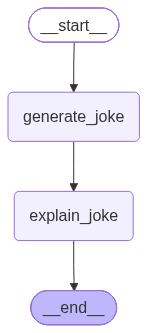

In [7]:
# Visualize Graph
display(Image(workflow.get_graph().draw_mermaid_png()))

In [8]:
# Run Workflow
config = {"configurable": {"thread_id": "joke_1"}}

result = workflow.invoke(
    {"topic": "programming"},
    config=config
)

print("Joke:", result["joke"])
print("\nExplanation:", result["explanation"])

Joke: Why do programmers prefer dark mode? Because light attracts bugs!

Explanation: The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.


In [9]:
# Inspect Checkpoint
snapshot = workflow.get_state(config)

print("Saved State:")
print(snapshot.values)

print("\nNext Nodes:", snapshot.next)
print("Checkpoint ID:", snapshot.config["configurable"]["checkpoint_id"])

Saved State:
{'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!', 'explanation': 'The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.'}

Next Nodes: ()
Checkpoint ID: 1f1e4b86-a25e-6535-8002-5a36773a6555


In [10]:
# View State History
history = list(workflow.get_state_history(config))

for i, snapshot in enumerate(reversed(history)):
    print(f"\nCheckpoint {i}")
    print("Next:", snapshot.next)
    print("State:", snapshot.values)


Checkpoint 0
Next: ('__start__',)
State: {}

Checkpoint 1
Next: ('generate_joke',)
State: {'topic': 'programming'}

Checkpoint 2
Next: ('explain_joke',)
State: {'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!'}

Checkpoint 3
Next: ()
State: {'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!', 'explanation': 'The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.'}


In [11]:
# Retrieve Saved Result
saved_state = workflow.get_state(config)

print("Topic:", saved_state.values["topic"])
print("Joke:", saved_state.values["joke"])
print("Explanation:", saved_state.values["explanation"])

Topic: programming
Joke: Why do programmers prefer dark mode? Because light attracts bugs!
Explanation: The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.


### Time Travel

In [12]:
# View Checkpoint History
history = list(workflow.get_state_history(config))

for i, snapshot in enumerate(history):
    print(f"\nCheckpoint {i}")
    print("State:", snapshot.values)
    print("Next:", snapshot.next)
    print("Checkpoint ID:", snapshot.config["configurable"]["checkpoint_id"])


Checkpoint 0
State: {'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!', 'explanation': 'The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.'}
Next: ()
Checkpoint ID: 1f1e4b86-a25e-6535-8002-5a36773a6555

Checkpoint 1
State: {'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!'}
Next: ('explain_joke',)
Checkpoint ID: 1f1e4b86-9da0-6aef-8001-1c2ec85e8991

Checkpoint 2
State: {'topic': 'programming'}
Next: ('generate_joke',)
Checkpoint ID: 1f1e4b86-8b0c-6e62-8000-3c42ab493a86

Checkpoin

In [13]:
# Select Checkpoint
checkpoint = next(
    s for s in history
    if s.next == ("explain_joke",)
)

print("Selected State:", checkpoint.values)
print("Next Node:", checkpoint.next)

Selected State: {'topic': 'programming', 'joke': 'Why do programmers prefer dark mode? Because light attracts bugs!'}
Next Node: ('explain_joke',)


In [14]:
# Update Checkpoint
new_config = workflow.update_state(
    checkpoint.config,
    {"joke": "Why do programmers prefer dark mode? Because light attracts bugs!"}
)

In [15]:
# Run New Branch
result = workflow.invoke(None, config=new_config)

print("Joke:", result["joke"])
print("Explanation:", result["explanation"])

Joke: Why do programmers prefer dark mode? Because light attracts bugs!
Explanation: The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests they avoid literal insects and, more cleverly, the metaphorical software bugs that might “follow” them in bright code. The punchline’s wordplay and the relatable idea that dark mode feels safer for coders make it funny.


In [16]:
# Run New Branch
result = workflow.invoke(None, config=new_config)

print("Joke:", result["joke"])
print("Explanation:", result["explanation"])

Joke: Why do programmers prefer dark mode? Because light attracts bugs!
Explanation: The joke plays on a double meaning of “bugs.” In programming, a “bug” is a software error, while in everyday life a bug is an insect attracted to light. By saying programmers prefer dark mode because “light attracts bugs,” it humorously suggests that avoiding bright screens keeps both software glitches and literal insects away, blending tech jargon with a familiar, literal observation.
